# Trabalho 02 — Redes Neurais: Fashion-MNIST

**UFSC · Sistemas Inteligentes (INE5633)**  
**Professora:** Nathalia da Cruz Alves  
**Entrega:** 15/11/2026

## Equipe e contribuições

| Estudante | Contribuição |
| --- | --- |
| Ana Luiza Bastos | Desenvolvimento da MLP e participação na seleção dos hiperparâmetros da CNN. |
| Rafael Nascimento | Desenvolvimento da CNN e participação na seleção dos seus hiperparâmetros. |

Neste trabalho, comparamos uma MLP e uma CNN na classificação das dez classes
do Fashion-MNIST. Também testamos combinações de hiperparâmetros e diferentes
números de camadas convolucionais, seguindo as implementações das aulas práticas.

## Organização do trabalho

Começamos pelo carregamento e pela preparação dos dados. Em seguida, treinamos
a MLP e a CNN com aumento de dados e comparamos suas curvas de perda e acurácia.
Na otimização, fizemos uma busca inicial de hiperparâmetros e outra comparação
com duas, três e quatro camadas convolucionais. Por fim, apresentamos a avaliação
no teste e as conclusões.

## 1. Ambiente e reprodutibilidade

Utilizamos TensorFlow/Keras, como nas aulas práticas, e Keras Tuner para a busca
de hiperparâmetros. Fixamos a semente em 42 para controlar a divisão dos dados e
as fontes usuais de aleatoriedade. Também registramos as versões das bibliotecas
e os dispositivos disponíveis, pois os resultados podem variar entre ambientes.

In [95]:
import gzip
import importlib.metadata
import json
from pathlib import Path
import platform
import struct
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
keras.utils.set_random_seed(SEED)

# O kernel deve partir desta pasta ou de um de seus subdiretórios.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'scripts' / 'baixar_dados.py').is_file()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError('Abra o notebook na pasta Trabalho 02 do repositório.')

DADOS = RAIZ / 'dados' / 'fashion-mnist'
RESULTADOS = RAIZ / 'resultados'
MODELOS = RAIZ / 'modelos'
for pasta in (RESULTADOS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

versoes = {'python': platform.python_version()}
for pacote in ('tensorflow', 'numpy', 'pandas', 'matplotlib', 'scikit-learn'):
    versoes[pacote] = importlib.metadata.version(pacote)
print(json.dumps(versoes, indent=2))
print('GPUs disponíveis:', tf.config.list_physical_devices('GPU'))
print('Seed:', SEED)
(RESULTADOS / 'ambiente.json').write_text(
    json.dumps({'seed': SEED, 'versoes': versoes}, indent=2), encoding='utf-8'
)

{
  "python": "3.13.14",
  "tensorflow": "2.21.0",
  "numpy": "2.4.6",
  "pandas": "3.0.5",
  "matplotlib": "3.11.1",
  "scikit-learn": "1.9.0"
}
GPUs disponíveis: []
Seed: 42


190

## 2. Carregamento do Fashion-MNIST

O Fashion-MNIST contém imagens de roupas de 28 × 28 pixels em escala de cinza,
distribuídas em dez classes. São 60.000 imagens no conjunto oficial de treino
e 10.000 no teste.

Carregamos os arquivos no formato IDX original. O download verifica a integridade
dos arquivos, e a leitura confere suas dimensões e os rótulos.

In [96]:
subprocess.run([sys.executable, str(RAIZ / 'scripts' / 'baixar_dados.py')], check=True)


def carregar_idx(prefixo):
    with gzip.open(DADOS / f'{prefixo}-images-idx3-ubyte.gz', 'rb') as arquivo:
        magic, quantidade, altura, largura = struct.unpack('>IIII', arquivo.read(16))
        assert magic == 2051 and (altura, largura) == (28, 28)
        imagens = np.frombuffer(arquivo.read(), dtype=np.uint8)
        assert imagens.size == quantidade * altura * largura
        imagens = imagens.reshape(quantidade, altura, largura)
    with gzip.open(DADOS / f'{prefixo}-labels-idx1-ubyte.gz', 'rb') as arquivo:
        magic, total_rotulos = struct.unpack('>II', arquivo.read(8))
        assert magic == 2049 and total_rotulos == quantidade
        rotulos = np.frombuffer(arquivo.read(), dtype=np.uint8)
        assert rotulos.size == quantidade and np.all(rotulos < 10)
    return imagens, rotulos


# Carregar o teste somente na seção 6, após selecionar o modelo.
X_oficial, y_oficial = carregar_idx('train')
assert X_oficial.shape == (60000, 28, 28)
print('Treino oficial:', X_oficial.shape, y_oficial.shape)
print('Pixels:', X_oficial.dtype, '| intervalo:', X_oficial.min(), X_oficial.max())

OK (já disponível): train-images-idx3-ubyte.gz
OK (já disponível): train-labels-idx1-ubyte.gz
OK (já disponível): t10k-images-idx3-ubyte.gz
OK (já disponível): t10k-labels-idx1-ubyte.gz
Dados disponíveis em: /home/jovyan/work/dados/fashion-mnist
Treino oficial: (60000, 28, 28) (60000,)
Pixels: uint8 | intervalo: 0 255


## 3. Separação de treino e validação

Separamos 20% do treino oficial para validação, mantendo a proporção das classes.
Assim, utilizamos 48.000 imagens para treino e 12.000 para validação, com a mesma
divisão em todos os experimentos. As 10.000 imagens de teste ficaram separadas
do treinamento e da seleção dos modelos.

A tabela mostra a quantidade de exemplos por classe, e o painel apresenta uma
imagem de treino de cada categoria. Traduzimos os nomes das classes, mantendo
a numeração original do dataset.

,classe,treino,validacao
0,Camiseta/top,4800,1200
1,Calça,4800,1200
2,Suéter,4800,1200
3,Vestido,4800,1200
4,Casaco,4800,1200
5,Sandália,4800,1200
6,Camisa,4800,1200
7,Tênis,4800,1200
8,Bolsa,4800,1200
9,Bota de cano curto,4800,1200


Treino: 48000 | Validação: 12000


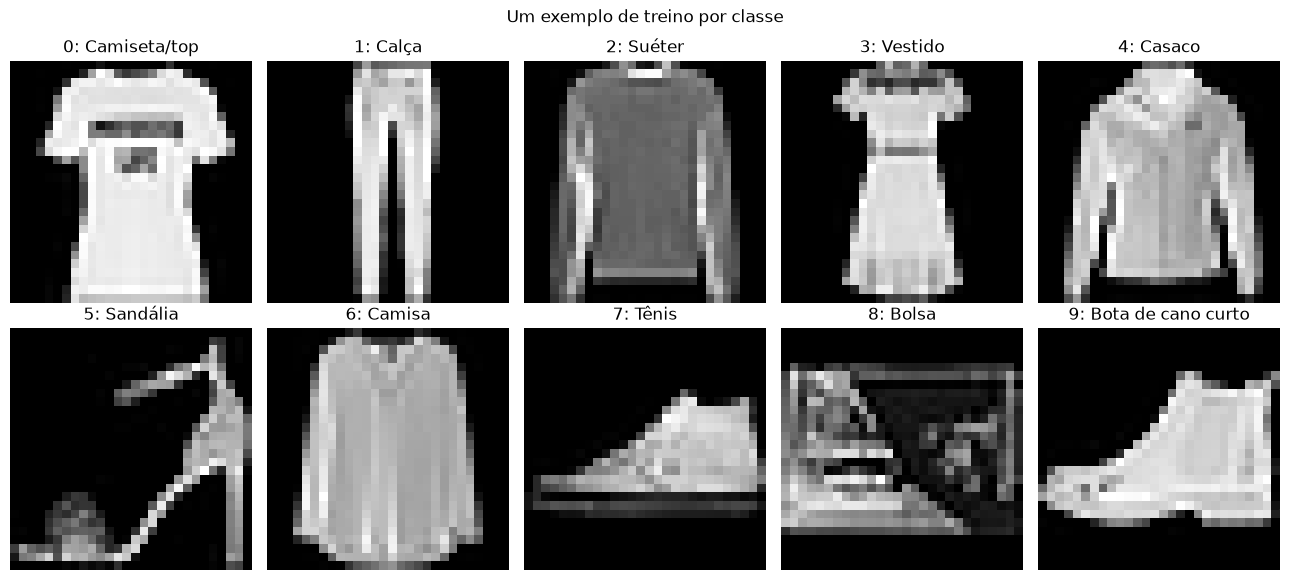

In [97]:
NOMES_CLASSES = [
    'Camiseta/top', 'Calça', 'Suéter', 'Vestido', 'Casaco',
    'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota de cano curto',
]
indices_treino, indices_validacao = train_test_split(
    np.arange(len(y_oficial)), test_size=0.2, random_state=SEED,
    stratify=y_oficial,
)
assert not np.intersect1d(indices_treino, indices_validacao).size
assert len(indices_treino) + len(indices_validacao) == len(y_oficial)
np.savez(RESULTADOS / 'divisao_dados.npz',
         treino=indices_treino, validacao=indices_validacao, seed=SEED)

contagens = pd.DataFrame({
    'classe': NOMES_CLASSES,
    'treino': np.bincount(y_oficial[indices_treino], minlength=10),
    'validacao': np.bincount(y_oficial[indices_validacao], minlength=10),
})
display(contagens)
print(f'Treino: {len(indices_treino)} | Validação: {len(indices_validacao)}')

fig, eixos = plt.subplots(2, 5, figsize=(13, 6))
for classe, eixo in enumerate(eixos.flat):
    candidatos = indices_treino[y_oficial[indices_treino] == classe]
    eixo.imshow(X_oficial[candidatos[0]], cmap='gray', vmin=0, vmax=255)
    eixo.set_title(f'{classe}: {NOMES_CLASSES[classe]}')
    eixo.axis('off')
fig.suptitle('Um exemplo de treino por classe')
fig.tight_layout()
fig.savefig(RESULTADOS / 'exemplos_treino.png', dpi=150, bbox_inches='tight')
plt.show()

### Normalização e formato das entradas

Convertemos os pixels para `float32` e dividimos os valores por 255, usando
a escala de 0 a 1. Mantivemos o formato `(28, 28, 1)` para a CNN. Na MLP,
a camada `Flatten` transforma cada imagem em um vetor de 784 valores.

O aumento de dados é aplicado somente durante o treino da CNN. Validação e
teste recebem as imagens normalizadas, sem transformações aleatórias.

In [98]:
X_train = X_oficial[indices_treino].astype('float32')[..., np.newaxis] / 255.0
X_val = X_oficial[indices_validacao].astype('float32')[..., np.newaxis] / 255.0
y_train = y_oficial[indices_treino]
y_val = y_oficial[indices_validacao]

assert X_train.shape == (48000, 28, 28, 1)
assert X_val.shape == (12000, 28, 28, 1)
assert 0 <= X_train.min() <= X_train.max() <= 1
print('Treino:', X_train.shape, y_train.shape, X_train.dtype)
print('Validação:', X_val.shape, y_val.shape, X_val.dtype)
print('Teste reservado: 10.000 imagens, ainda não carregadas pelo notebook.')

Treino: (48000, 28, 28, 1) (48000,) float32
Validação: (12000, 28, 28, 1) (12000,) float32
Teste reservado: 10.000 imagens, ainda não carregadas pelo notebook.


## 4. MLP: implementação, treinamento e análise

### Arquitetura e métricas

Adaptamos a MLP da Aula 19 — Perceptron, da Profa. Nathalia da Cruz Alves,
para classificar as dez categorias do Fashion-MNIST. Mantivemos a construção
com `Sequential`, camadas densas, ativação `tanh` e otimizador Adam.

A rede recebe os 784 pixels após o `Flatten`, possui uma camada oculta com
128 neurônios e uma saída com dez neurônios e `softmax`. Essa saída representa
as probabilidades das classes. Usamos taxa de aprendizagem 0,001 e a perda
`sparse_categorical_crossentropy`, adequada aos rótulos inteiros de 0 a 9.
A rede não possui camadas convolucionais.

Para $N$ imagens, a **acurácia** é a proporção de previsões corretas:
$\mathrm{acurácia} = \frac{1}{N}\sum_i \mathbf{1}(\hat{y}_i = y_i)$.
A **perda** é a média do negativo do logaritmo da probabilidade atribuída
à classe verdadeira: $\mathrm{loss} = -\frac{1}{N}\sum_i \log p(y_i\mid x_i)$.
O treinamento ajusta os pesos para reduzir essa perda.

As métricas não são proporcionais. Se a classe correta já for a mais provável,
aumentar sua probabilidade de 0,4 para 0,8 mantém o acerto, mas reduz a perda
de aproximadamente 0,916 para 0,223. Da mesma forma, erros com muita confiança
podem aumentar a perda sem alterar a quantidade de acertos.

In [99]:
# Adaptado da Aula Prática 19, treinar_mlp.
tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_mlp = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='tanh'),
    tf.keras.layers.Dense(10, activation='softmax'),
])

model_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

model_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Treinamento da MLP

Treinamos a MLP por 20 épocas, com lotes de 32 imagens e sem parada antecipada.
Cada época corresponde a uma passagem pelo conjunto de treino. Ao final de cada
época, avaliamos as mesmas 12.000 imagens de validação, sem atualizar os pesos.

O `fit` registra perda e acurácia de treino e validação. Salvamos o histórico
e o modelo da última época. A tabela abaixo resume o início e o fim do treino.

In [100]:
history_mlp = model_mlp.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=2,
)

historico_mlp = pd.DataFrame(history_mlp.history)
historico_mlp.index = pd.RangeIndex(1, len(historico_mlp) + 1, name='epoca')
historico_mlp.to_csv(RESULTADOS / 'historico_mlp.csv')
model_mlp.save(MODELOS / 'mlp.keras')

display(historico_mlp.iloc[[0, -1]])
print('Época de menor loss de validação:', historico_mlp['val_loss'].idxmin())

Epoch 1/20
1500/1500 - 5s - 3ms/step - accuracy: 0.8197 - loss: 0.4992 - val_accuracy: 0.8455 - val_loss: 0.4168
Epoch 2/20
1500/1500 - 4s - 2ms/step - accuracy: 0.8612 - loss: 0.3816 - val_accuracy: 0.8608 - val_loss: 0.3745
Epoch 3/20
1500/1500 - 4s - 3ms/step - accuracy: 0.8751 - loss: 0.3438 - val_accuracy: 0.8755 - val_loss: 0.3409
Epoch 4/20
1500/1500 - 4s - 3ms/step - accuracy: 0.8835 - loss: 0.3179 - val_accuracy: 0.8779 - val_loss: 0.3323
Epoch 5/20
1500/1500 - 3s - 2ms/step - accuracy: 0.8902 - loss: 0.2970 - val_accuracy: 0.8800 - val_loss: 0.3297
Epoch 6/20
1500/1500 - 5s - 3ms/step - accuracy: 0.8971 - loss: 0.2799 - val_accuracy: 0.8827 - val_loss: 0.3278
Epoch 7/20
1500/1500 - 5s - 3ms/step - accuracy: 0.9023 - loss: 0.2662 - val_accuracy: 0.8825 - val_loss: 0.3296
Epoch 8/20
1500/1500 - 5s - 3ms/step - accuracy: 0.9065 - loss: 0.2532 - val_accuracy: 0.8834 - val_loss: 0.3295
Epoch 9/20
1500/1500 - 3s - 2ms/step - accuracy: 0.9110 - loss: 0.2417 - val_accuracy: 0.8837 - 

,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.819708,0.499190,0.8455,0.416802
20,0.941229,0.165835,0.8840,0.360869


Época de menor loss de validação: 6


### Curvas de treino e validação

Os gráficos apresentam a perda e a acurácia por época, com as curvas de treino
e validação lado a lado, seguindo a função `plot_metrics` da aula. A comparação
permite observar o aprendizado e a diferença entre os dois conjuntos.

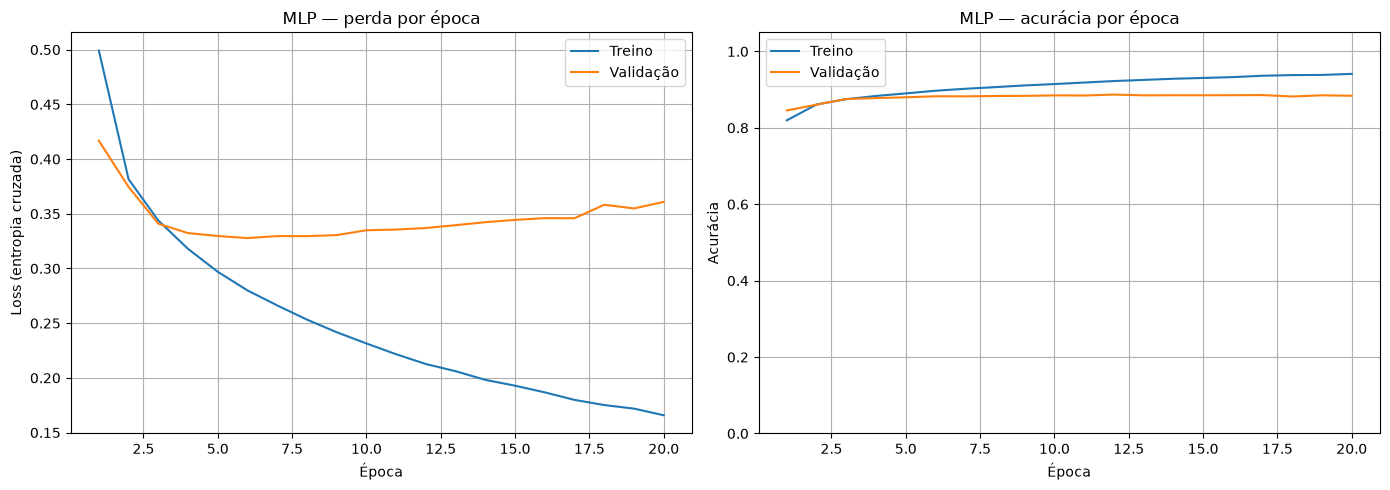

In [101]:
# Adaptado de plot_metrics da aula, incluindo as curvas de validação.
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(historico_mlp.index, historico_mlp['loss'], label='Treino')
ax[0].plot(historico_mlp.index, historico_mlp['val_loss'], label='Validação')
ax[0].set_title('MLP — perda por época')
ax[0].set_xlabel('Época')
ax[0].set_ylabel('Loss (entropia cruzada)')
ax[0].grid(True)
ax[0].legend()

ax[1].plot(historico_mlp.index, historico_mlp['accuracy'], label='Treino')
ax[1].plot(historico_mlp.index, historico_mlp['val_accuracy'], label='Validação')
ax[1].set_title('MLP — acurácia por época')
ax[1].set_xlabel('Época')
ax[1].set_ylabel('Acurácia')
ax[1].set_ylim(0, 1.05)
ax[1].grid(True)
ax[1].legend()

fig.tight_layout()
fig.savefig(RESULTADOS / 'curvas_mlp.png', dpi=150, bbox_inches='tight')
plt.show()

### Sobreajuste na MLP

Destacamos a época 6, que apresentou a menor perda de validação. Depois dela,
a perda de treino continuou caindo, enquanto a de validação aumentou.
A acurácia de treino também avançou mais que a de validação. Esse comportamento
indica sobreajuste nas épocas seguintes.

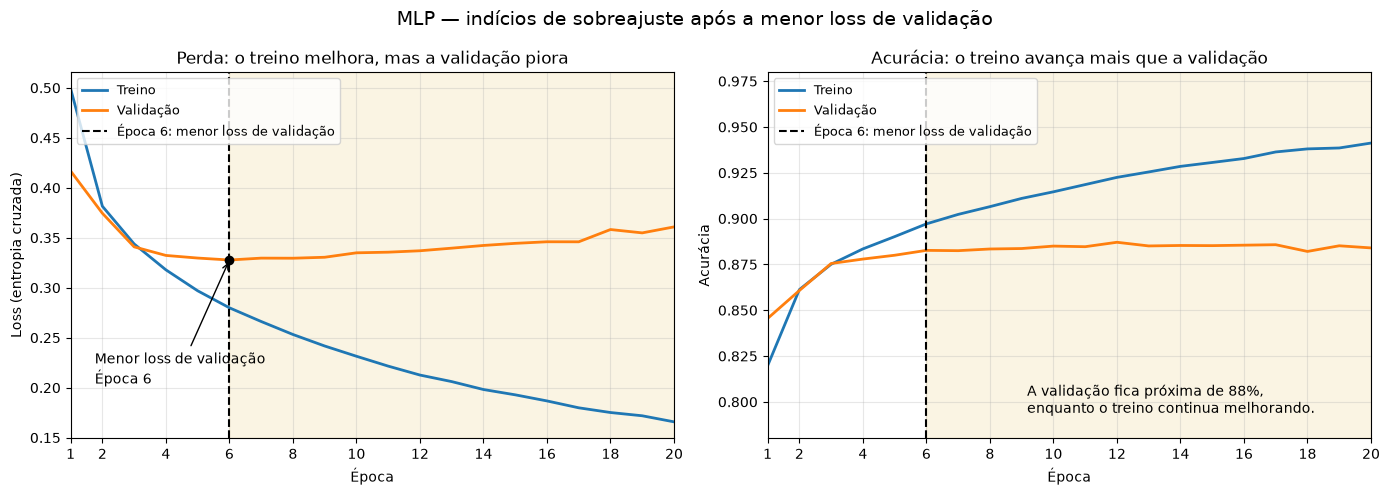

In [102]:
# Base: plot_metrics da Aula 19, com validação e destaques para a análise.
epoca_menor_loss = int(historico_mlp['val_loss'].idxmin())
epocas = historico_mlp.index
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epocas, historico_mlp['loss'], label='Treino', linewidth=2)
ax[0].plot(epocas, historico_mlp['val_loss'], label='Validação', linewidth=2)
ax[0].scatter(epoca_menor_loss, historico_mlp.loc[epoca_menor_loss, 'val_loss'],
              color='black', zorder=5)
ax[0].annotate(
    f'Menor loss de validação\nÉpoca {epoca_menor_loss}',
    xy=(epoca_menor_loss, historico_mlp.loc[epoca_menor_loss, 'val_loss']),
    xytext=(0.04, 0.15), textcoords='axes fraction',
    arrowprops={'arrowstyle': '->', 'color': 'black'},
)
ax[0].set_title('Perda: o treino melhora, mas a validação piora')
ax[0].set_ylabel('Loss (entropia cruzada)')

ax[1].plot(epocas, historico_mlp['accuracy'], label='Treino', linewidth=2)
ax[1].plot(epocas, historico_mlp['val_accuracy'], label='Validação', linewidth=2)
ax[1].set_title('Acurácia: o treino avança mais que a validação')
ax[1].set_ylabel('Acurácia')
ax[1].set_ylim(0.78, 0.98)
ax[1].text(0.43, 0.07, 'A validação fica próxima de 88%,\n'
           'enquanto o treino continua melhorando.',
           transform=ax[1].transAxes, fontsize=10)

for eixo in ax:
    eixo.axvline(epoca_menor_loss, color='black', linestyle='--',
                 label=f'Época {epoca_menor_loss}: menor loss de validação')
    eixo.axvspan(epoca_menor_loss, epocas[-1], color='goldenrod', alpha=0.12)
    eixo.set_xlabel('Época')
    eixo.set_xticks([epocas[0], *range(2, int(epocas[-1]) + 1, 2)])
    eixo.set_xlim(epocas[0], epocas[-1])
    eixo.grid(True, alpha=0.3)
    eixo.legend(loc='upper left', fontsize=9)

fig.suptitle('MLP — indícios de sobreajuste após a menor loss de validação', fontsize=14)
fig.tight_layout()
fig.savefig(RESULTADOS / 'analise_sobreajuste_mlp.png', dpi=150, bbox_inches='tight')
plt.show()


### Resultados da MLP

| Época | Loss de treino | Acurácia de treino | Loss de validação | Acurácia de validação |
| --- | ---: | ---: | ---: | ---: |
| 1 | 0,4992 | 81,97% | 0,4168 | 84,55% |
| 6 | 0,2799 | 89,71% | 0,3278 | 88,27% |
| 20 | 0,1658 | 94,12% | 0,3609 | 88,40% |

Consideramos o resultado satisfatório como ponto de partida: a MLP chegou
a 88,40% de acurácia de validação. Porém, houve sobreajuste após a época 6.
Até a época 20, a perda de treino caiu de 0,2799 para 0,1658, enquanto a de
validação subiu de 0,3278 para 0,3609. A diferença final entre as acurácias
de treino e validação foi de 5,72 pontos percentuais.

Nesse mesmo intervalo, a acurácia de validação passou de 88,27% para 88,40%,
apesar do aumento da perda. Isso mostra que acertar uma quantidade semelhante
de imagens não significa atribuir probabilidades igualmente boas às classes.

A validação indica que a rede aprendeu padrões úteis em imagens fora do treino,
mas continuar treinando trouxe pouco ganho nesse conjunto. O modelo salvo
corresponde à época 20; os pesos da época 6 não foram recuperados.
Não avaliamos a MLP no teste.

## 5. CNN com aumento de dados

### Aumento de dados

Utilizamos como base a CNN com aumento de dados da Aula 21, da Profa. Nathalia
da Cruz Alves. O aumento apresenta pequenas variações das imagens durante o
treino, reduzindo a dependência de posições, orientações e escalas específicas.
Isso pode ajudar a rede a generalizar para novas imagens.

Aplicamos três transformações:

- `RandomRotation(0.05)`: rotações de até aproximadamente ±18 graus. Reduzimos
  o fator 0,1 da aula para preservar melhor a orientação das roupas.
- `RandomTranslation(0.1, 0.1)`: deslocamentos de até 10% na altura e na largura.
- `RandomZoom(0.1)`: pequenas ampliações ou reduções de escala.

O painel mostra uma imagem original e oito versões transformadas. As camadas
de aumento ficam ativas apenas no treino; validação e teste preservam as imagens
normalizadas, sem essas transformações.

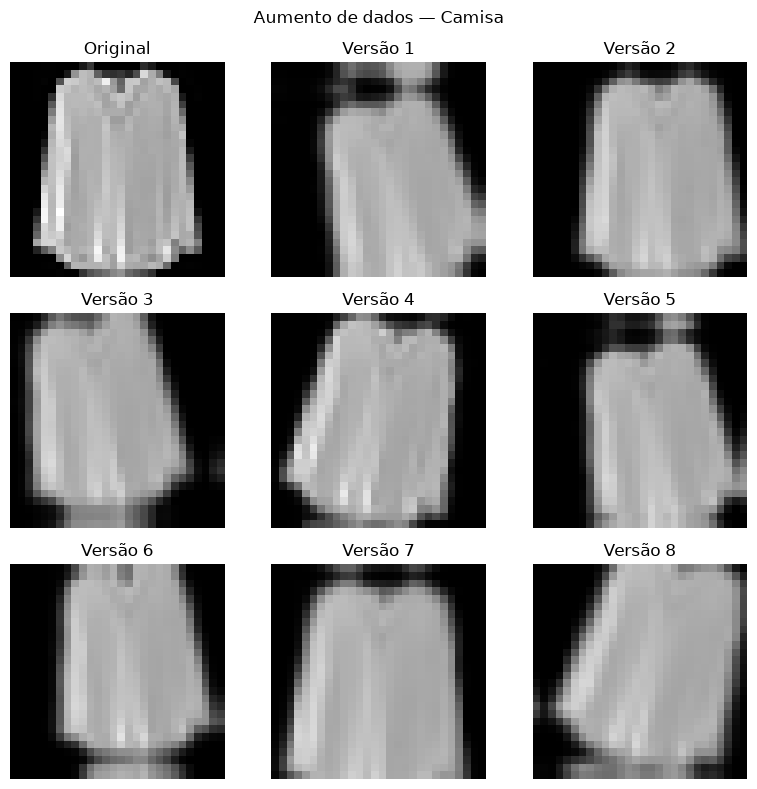

Conferido: aumento de dados desativado em modo de avaliação.


In [103]:
# Adaptado da Aula Prática 21, data_augmentation e sua visualização.
tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

data_augmentation = keras.Sequential([
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    keras.layers.RandomZoom(0.1),
], name='aumento_dados')

img = X_train[0]
fig, eixos = plt.subplots(3, 3, figsize=(8, 8))
eixos.flat[0].imshow(img.squeeze(), cmap='gray', vmin=0, vmax=1)
eixos.flat[0].set_title('Original')
eixos.flat[0].axis('off')
for i, eixo in enumerate(eixos.flat[1:], start=1):
    augmented = data_augmentation(tf.expand_dims(img, 0), training=True)
    eixo.imshow(augmented[0].numpy().squeeze(), cmap='gray', vmin=0, vmax=1)
    eixo.set_title(f'Versão {i}')
    eixo.axis('off')
fig.suptitle(f'Aumento de dados — {NOMES_CLASSES[int(y_train[0])]}')
fig.tight_layout()
fig.savefig(RESULTADOS / 'aumento_dados_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

# Em avaliação, o aumento de dados deve devolver as imagens sem transformação.
np.testing.assert_allclose(
    data_augmentation(X_val[:32], training=False).numpy(), X_val[:32],
)
print('Conferido: aumento de dados desativado em modo de avaliação.')

### Arquitetura da CNN

As convoluções aplicam filtros aprendidos a regiões das imagens, explorando
a relação espacial entre os pixels. Seguimos a arquitetura da aula 21:
três camadas `Conv2D`, com 8, 16 e 32 filtros de 3 × 3 e ativação ReLU,
seguidas de `MaxPooling2D` de 2 × 2, `Flatten`, uma camada densa com 64 neurônios
e saída com dez neurônios e `softmax`.

A ReLU retorna o maior valor entre zero e a entrada. O pooling reduz as dimensões
dos mapas, mantendo o maior valor de cada janela. Como as convoluções usam
`padding='valid'`, as dimensões passam de 28 para 26, 24 e 22; após o pooling,
ficam em 11 × 11 × 32. A rede possui 254.410 parâmetros treináveis.

Inserimos o aumento de dados após a entrada e compilamos a rede com Adam,
taxa de aprendizagem 0,001, `sparse_categorical_crossentropy` e acurácia,
mantendo o otimizador e a perda utilizados na MLP.

In [104]:
# Adaptado da Aula Prática 21, model3 (CNN com aumento de dados).
model_cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    data_augmentation,
    keras.layers.Conv2D(filters=8, kernel_size=(3, 3), activation='relu'),
    keras.layers.Conv2D(filters=16, kernel_size=(3, 3), activation='relu'),
    keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax'),
])

model_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_dados (Sequential)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 22, 22, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3872)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       247,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 254,410 (993.79 KB)

 Trainable params: 254,410 (993.79 KB)

 Non-trainable params: 0 (0.00 B)

### Treinamento da CNN

Treinamos por 20 épocas, com lotes de 32, usando a mesma divisão e a mesma
quantidade de épocas da MLP. Utilizamos `validation_data` para manter exatamente
as mesmas imagens de validação nos experimentos.

As métricas de treino são calculadas com aumento de dados e pesos em atualização.
Na validação, os pesos ficam fixos e não há aumento. Por isso, uma acurácia de
validação maior que a de treino pode ocorrer normalmente.

Salvamos o histórico e o modelo da última época. A tabela resume a primeira
época, a de menor perda de validação e a última.

In [105]:
history_cnn = model_cnn.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=2,
)

historico_cnn = pd.DataFrame(history_cnn.history)
historico_cnn.index = pd.RangeIndex(1, len(historico_cnn) + 1, name='epoca')
historico_cnn.to_csv(RESULTADOS / 'historico_cnn.csv')
model_cnn.save(MODELOS / 'cnn.keras')

epoca_menor_loss_cnn = historico_cnn['val_loss'].idxmin()
epocas_resumo_cnn = sorted({1, epoca_menor_loss_cnn, len(historico_cnn)})
display(historico_cnn.loc[epocas_resumo_cnn])
print('Época de menor loss de validação:', epoca_menor_loss_cnn)

Epoch 1/20
1500/1500 - 24s - 16ms/step - accuracy: 0.7365 - loss: 0.6955 - val_accuracy: 0.7741 - val_loss: 0.6354
Epoch 2/20
1500/1500 - 22s - 15ms/step - accuracy: 0.8018 - loss: 0.5231 - val_accuracy: 0.8248 - val_loss: 0.4992
Epoch 3/20
1500/1500 - 20s - 13ms/step - accuracy: 0.8235 - loss: 0.4656 - val_accuracy: 0.8393 - val_loss: 0.4638
Epoch 4/20
1500/1500 - 20s - 14ms/step - accuracy: 0.8384 - loss: 0.4266 - val_accuracy: 0.8639 - val_loss: 0.3797
Epoch 5/20
1500/1500 - 21s - 14ms/step - accuracy: 0.8486 - loss: 0.4045 - val_accuracy: 0.8662 - val_loss: 0.3619
Epoch 6/20
1500/1500 - 21s - 14ms/step - accuracy: 0.8539 - loss: 0.3876 - val_accuracy: 0.8773 - val_loss: 0.3504
Epoch 7/20
1500/1500 - 21s - 14ms/step - accuracy: 0.8603 - loss: 0.3734 - val_accuracy: 0.8832 - val_loss: 0.3313
Epoch 8/20
1500/1500 - 21s - 14ms/step - accuracy: 0.8635 - loss: 0.3630 - val_accuracy: 0.8793 - val_loss: 0.3333
Epoch 9/20
1500/1500 - 20s - 13ms/step - accuracy: 0.8674 - loss: 0.3559 - val_a

,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.736500,0.695452,0.774083,0.635399
16,0.882771,0.313724,0.891583,0.306862
20,0.887104,0.304789,0.889917,0.327151


Época de menor loss de validação: 16


### Curvas da CNN e comparação com a MLP

Os gráficos mostram perda e acurácia de treino e validação ao longo das 20 épocas.
A tabela compara os resultados da última época de cada modelo. A validação usa
as mesmas imagens sem transformações, enquanto o treino da CNN inclui aumento
de dados. A comparação considera as duas configurações completas, pois a
arquitetura e o uso de aumento mudam juntos.

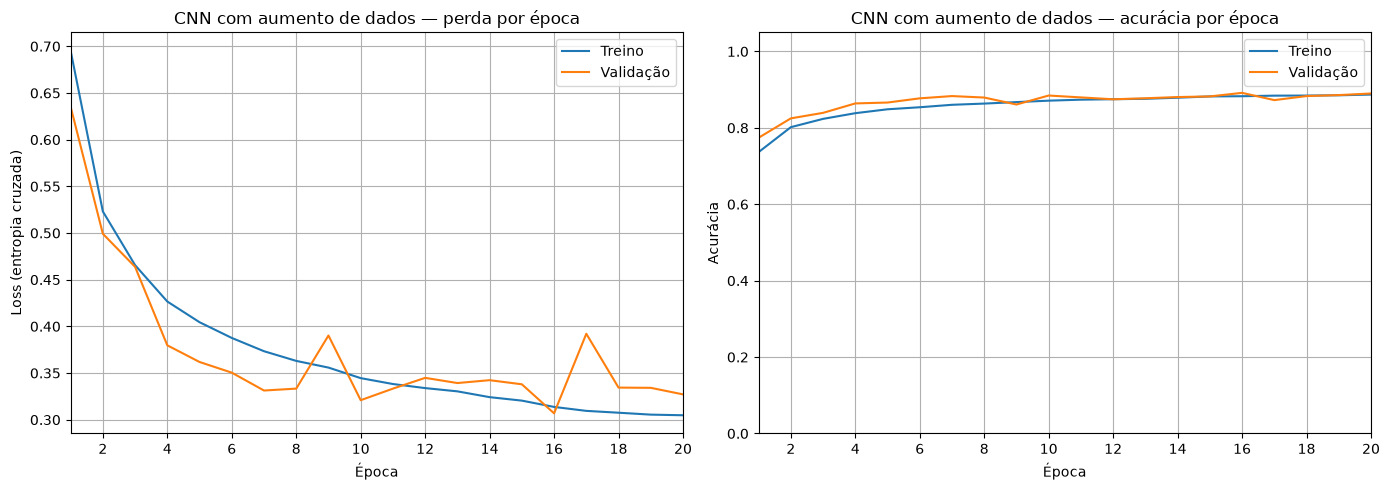

,accuracy,loss,val_accuracy,val_loss,epocas
modelo,,,,,
MLP,0.941229,0.165835,0.884000,0.360869,20
CNN com aumento de dados,0.887104,0.304789,0.889917,0.327151,20


In [106]:
# Adaptado dos gráficos de history3 da Aula Prática 21.
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(historico_cnn.index, historico_cnn['loss'], label='Treino')
ax[0].plot(historico_cnn.index, historico_cnn['val_loss'], label='Validação')
ax[0].set_title('CNN com aumento de dados — perda por época')
ax[0].set_xlabel('Época')
ax[0].set_ylabel('Loss (entropia cruzada)')
ax[0].grid(True)
ax[0].legend()

ax[1].plot(historico_cnn.index, historico_cnn['accuracy'], label='Treino')
ax[1].plot(historico_cnn.index, historico_cnn['val_accuracy'], label='Validação')
ax[1].set_title('CNN com aumento de dados — acurácia por época')
ax[1].set_xlabel('Época')
ax[1].set_ylabel('Acurácia')
ax[1].set_ylim(0, 1.05)
ax[1].grid(True)
ax[1].legend()

for eixo in ax:
    eixo.set_xticks(range(2, len(historico_cnn) + 1, 2))
    eixo.set_xlim(1, len(historico_cnn))

fig.tight_layout()
fig.savefig(RESULTADOS / 'curvas_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

comparacao_modelos = pd.DataFrame([
    historico_mlp.iloc[-1], historico_cnn.iloc[-1],
], index=['MLP', 'CNN com aumento de dados'])
comparacao_modelos.index.name = 'modelo'
comparacao_modelos['epocas'] = [len(historico_mlp), len(historico_cnn)]
display(comparacao_modelos)
comparacao_modelos.to_csv(RESULTADOS / 'comparacao_mlp_cnn.csv')

### Resultados da CNN

| Época | Loss de treino | Acurácia de treino | Loss de validação | Acurácia de validação |
| --- | ---: | ---: | ---: | ---: |
| 1 | 0,6955 | 73,65% | 0,6354 | 77,41% |
| 16 | 0,3137 | 88,28% | 0,3069 | 89,16% |
| 20 | 0,3048 | 88,71% | 0,3272 | 88,99% |

A CNN apresentou aprendizado nos dois conjuntos, com a melhor perda e a maior
acurácia de validação na época 16. No fim, a perda de treino continuou caindo,
mas a de validação subiu de 0,3069 para 0,3272. Há indícios de sobreajuste nesse
trecho, embora as curvas também apresentem oscilações. Não observamos um padrão
predominante de subajuste.

| Modelo — última época | Loss de treino | Acurácia de treino | Loss de validação | Acurácia de validação |
| --- | ---: | ---: | ---: | ---: |
| MLP | 0,1658 | 94,12% | 0,3609 | 88,40% |
| CNN com aumento de dados | 0,3048 | 88,71% | 0,3272 | 88,99% |

Na última época, a CNN superou a MLP em 0,59 ponto percentual de acurácia de
validação e apresentou menor perda. Consideramos o resultado satisfatório,
com menor afastamento entre treino e validação. Essa diferença precisa considerar
que o treino da CNN recebe imagens transformadas; ela não comprova, por si só,
ausência de sobreajuste. Também não isolamos o efeito do aumento de dados,
pois não treinamos a mesma CNN sem as transformações.

As métricas novamente não variaram de forma proporcional: entre as épocas 13
e 14, a acurácia de validação subiu de 87,74% para 88,06%, mas a perda também
subiu, de 0,3393 para 0,3424. O modelo salvo corresponde à época 20.

## 5.1. Experimentação e otimização da CNN

### Hiperparâmetros e configuração da busca

Seguimos a função `build_model(hp)` e o `keras_tuner.RandomSearch` da Aula 23,
da Profa. Nathalia da Cruz Alves. Hiperparâmetros são escolhas definidas antes
do treino, diferentemente dos pesos aprendidos. O Random Search sorteia
combinações e compara seus resultados de validação.

Definimos as seguintes opções:

| Hiperparâmetro | Valores |
| --- | --- |
| Filtros da primeira convolução | 8 e 16 |
| Filtros da segunda convolução | 16 e 32 |
| Neurônios da camada densa | 32 e 64 |
| Dropout | 0,0 e 0,3 |
| Taxa de aprendizagem | 0,001 e 0,0001 |

Filtros e neurônios alteram a capacidade da rede. O Dropout desativa parte
das ativações durante o treino e pode reduzir o sobreajuste. A taxa de
aprendizagem controla o tamanho das atualizações dos pesos.

Realizamos cinco tentativas de cinco épocas, com lotes de 32, entre 32
combinações possíveis. Selecionamos pela maior acurácia de validação,
sem usar o conjunto de teste.

In [107]:
import keras_tuner as kt

# EDITE AQUI: as listas contêm os valores que o Random Search pode sortear.
HIPERPARAMETROS = {
    'filters_1': [8, 16],
    'filters_2': [16, 32],
    'dense_units': [32, 64],
    'dropout_rate': [0.0, 0.3],
    'learning_rate': [0.001, 0.0001],
}
MAX_TENTATIVAS = 5
EPOCAS_POR_TENTATIVA = 5
BATCH_SIZE_BUSCA = 32
NOME_BUSCA = 'fashion_mnist_busca_01'  # Use outro nome para uma nova configuração.

PASTA_BUSCAS = RESULTADOS / 'buscas_cnn'
PASTA_BUSCA = PASTA_BUSCAS / NOME_BUSCA
configuracao_busca = {
    'hiperparametros': HIPERPARAMETROS,
    'max_tentativas': MAX_TENTATIVAS,
    'epocas_por_tentativa': EPOCAS_POR_TENTATIVA,
    'batch_size': BATCH_SIZE_BUSCA,
    'seed': SEED,
    'objetivo': 'val_accuracy',
    'arquitetura': 'CNN do item 2 com Dropout após Dense',
}
arquivo_configuracao = PASTA_BUSCA / 'configuracao_busca.json'
if arquivo_configuracao.exists():
    assert json.loads(arquivo_configuracao.read_text()) == configuracao_busca, (
        'Configuração diferente da busca salva. Escolha um novo NOME_BUSCA.'
    )
PASTA_BUSCA.mkdir(parents=True, exist_ok=True)
arquivo_configuracao.write_text(
    json.dumps(configuracao_busca, indent=2, ensure_ascii=False), encoding='utf-8',
)

print('Keras Tuner:', kt.__version__)
display(pd.DataFrame([
    {'hiperparametro': nome, 'valores': valores}
    for nome, valores in HIPERPARAMETROS.items()
]))
print(f'Busca: {NOME_BUSCA} | até {MAX_TENTATIVAS} tentativas')
print(f'Épocas por tentativa: {EPOCAS_POR_TENTATIVA} | lote: {BATCH_SIZE_BUSCA}')

Keras Tuner: 1.4.8


,hiperparametro,valores
0,filters_1,"[8, 16]"
1,filters_2,"[16, 32]"
2,dense_units,"[32, 64]"
3,dropout_rate,"[0.0, 0.3]"
4,learning_rate,"[0.001, 0.0001]"


Busca: fashion_mnist_busca_01 | até 5 tentativas
Épocas por tentativa: 5 | lote: 32


### Construção dos modelos da busca

Mantivemos as três convoluções e o aumento de dados da CNN anterior, com
32 filtros fixos na terceira convolução. A função cria uma rede para cada
combinação, variando os filtros das duas primeiras camadas, os neurônios densos,
o Dropout e a taxa de aprendizagem.

Acrescentamos o Dropout após a camada densa, como na aula 23. Assim como o aumento
de dados, ele atua somente durante o treinamento. Mantivemos a sequência de
camadas da CNN inicial, sem acrescentar BatchNormalization.

In [108]:
# Adaptado de build_model(hp) da Aula Prática 23 e da CNN do item 2.
def build_model(hp):
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        keras.Sequential([
            keras.layers.RandomRotation(0.05),
            keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
            keras.layers.RandomZoom(0.1),
        ], name='aumento_dados'),
        keras.layers.Conv2D(
            filters=hp.Choice('filters_1', HIPERPARAMETROS['filters_1']),
            kernel_size=(3, 3), activation='relu',
        ),
        keras.layers.Conv2D(
            filters=hp.Choice('filters_2', HIPERPARAMETROS['filters_2']),
            kernel_size=(3, 3), activation='relu',
        ),
        keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Flatten(),
        keras.layers.Dense(
            units=hp.Choice('dense_units', HIPERPARAMETROS['dense_units']),
            activation='relu',
        ),
        keras.layers.Dropout(
            rate=hp.Choice('dropout_rate', HIPERPARAMETROS['dropout_rate']),
        ),
        keras.layers.Dense(10, activation='softmax'),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=hp.Choice('learning_rate', HIPERPARAMETROS['learning_rate']),
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

### Random Search

Cada tentativa usa as mesmas imagens de treino e validação e executa cinco
épocas, sem parada antecipada. O tuner guarda os pesos da época com maior
acurácia de validação em cada tentativa. Fixamos a semente em 42 e mantivemos
`overwrite=False` para preservar os experimentos salvos.

In [109]:
keras.utils.set_random_seed(SEED)
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=MAX_TENTATIVAS,
    executions_per_trial=1,
    seed=SEED,
    directory=str(PASTA_BUSCAS),
    project_name=NOME_BUSCA,
    overwrite=False,
)

tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCAS_POR_TENTATIVA,
    batch_size=BATCH_SIZE_BUSCA,
    verbose=2,
)

Reloading Tuner from /home/jovyan/work/resultados/buscas_cnn/fashion_mnist_busca_01/tuner0.json


### Tabela dos experimentos

A tabela reúne as combinações testadas, as épocas e as métricas registradas
na época selecionada por acurácia de validação. Ordenamos as tentativas da maior
para a menor acurácia. Os identificadores começam em zero; a numeração das
épocas começa em um.

In [110]:
# Adaptado da tabela de trials da Aula Prática 23.
resultados_busca = []
for trial in tuner.oracle.trials.values():
    linha = {
        'tentativa': trial.trial_id,
        'status': trial.status,
        **trial.hyperparameters.values,
        'camadas_conv': 3,
        'filters_3': 32,
        'batch_size': BATCH_SIZE_BUSCA,
        'epocas_executadas': EPOCAS_POR_TENTATIVA if trial.status == 'COMPLETED' else None,
    }
    if trial.score is not None:
        linha['melhor_epoca'] = int(trial.best_step) + 1
        for metrica in ('loss', 'accuracy', 'val_loss', 'val_accuracy'):
            linha[metrica] = trial.metrics.get_best_value(metrica)
    resultados_busca.append(linha)

experimentos_cnn = pd.DataFrame(resultados_busca).sort_values(
    'val_accuracy', ascending=False, na_position='last',
).reset_index(drop=True)
experimentos_cnn.insert(0, 'posicao', range(1, len(experimentos_cnn) + 1))
display(experimentos_cnn)
experimentos_cnn.to_csv(RESULTADOS / 'experimentos_cnn.csv', index=False)
experimentos_cnn.to_csv(PASTA_BUSCA / 'experimentos_cnn.csv', index=False)

,posicao,tentativa,status,filters_1,filters_2,dense_units,dropout_rate,learning_rate,camadas_conv,filters_3,batch_size,epocas_executadas,melhor_epoca,loss,accuracy,val_loss,val_accuracy
0,1,4,COMPLETED,8,32,64,0.3,0.0010,3,32,32,5,5,0.484043,0.820687,0.390149,0.862417
1,2,3,COMPLETED,16,16,32,0.0,0.0010,3,32,32,5,4,0.454338,0.830125,0.430208,0.851250
2,3,1,COMPLETED,8,32,32,0.0,0.0010,3,32,32,5,5,0.420889,0.842208,0.411808,0.850417
3,4,2,COMPLETED,16,32,64,0.0,0.0001,3,32,32,5,5,0.568676,0.787437,0.543046,0.796167
4,5,0,COMPLETED,16,16,32,0.0,0.0001,3,32,32,5,5,0.604011,0.775292,0.566175,0.786000


### Melhor modelo da busca inicial

Recuperamos os pesos da melhor época com `get_best_models(1)` e os
hiperparâmetros com `get_best_hyperparameters(1)`, seguindo a aula 23.
Salvamos o modelo e sua configuração, sem realizar outro treinamento.

In [111]:
melhor_trial = tuner.oracle.get_best_trials(num_trials=1)[0]
melhores_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
melhor_modelo = tuner.get_best_models(num_models=1)[0]

melhor_configuracao = {
    'nome_busca': NOME_BUSCA,
    'tentativa': melhor_trial.trial_id,
    'melhor_epoca': int(melhor_trial.best_step) + 1,
    'hiperparametros': melhores_hp.values,
    'val_accuracy': float(melhor_trial.score),
    'val_loss': float(melhor_trial.metrics.get_best_value('val_loss')),
    'configuracao_busca': configuracao_busca,
}
melhor_modelo.save(MODELOS / 'melhor_cnn.keras')
(MODELOS / 'melhor_cnn_configuracao.json').write_text(
    json.dumps(melhor_configuracao, indent=2, ensure_ascii=False), encoding='utf-8',
)
print(json.dumps(melhor_configuracao, indent=2, ensure_ascii=False))
melhor_modelo.summary()

{
  "nome_busca": "fashion_mnist_busca_01",
  "tentativa": "4",
  "melhor_epoca": 5,
  "hiperparametros": {
    "filters_1": 8,
    "filters_2": 32,
    "dense_units": 64,
    "dropout_rate": 0.3,
    "learning_rate": 0.001
  },
  "val_accuracy": 0.862416684627533,
  "val_loss": 0.3901488780975342,
  "configuracao_busca": {
    "hiperparametros": {
      "filters_1": [
        8,
        16
      ],
      "filters_2": [
        16,
        32
      ],
      "dense_units": [
        32,
        64
      ],
      "dropout_rate": [
        0.0,
        0.3
      ],
      "learning_rate": [
        0.001,
        0.0001
      ]
    },
    "max_tentativas": 5,
    "epocas_por_tentativa": 5,
    "batch_size": 32,
    "seed": 42,
    "objetivo": "val_accuracy",
    "arquitetura": "CNN do item 2 com Dropout após Dense"
  }
}


/opt/conda/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_dados (Sequential)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         2,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 22, 22, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3872)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       247,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 260,186 (1016.35 KB)

 Trainable params: 260,186 (1016.35 KB)

 Non-trainable params: 0 (0.00 B)

### Análise da busca inicial

As cinco tentativas foram concluídas. A melhor combinação utilizou 8 e 32
filtros nas duas primeiras convoluções, 64 neurônios densos, Dropout 0,3
e taxa de aprendizagem 0,001. A terceira convolução manteve 32 filtros.
Na época 5, essa rede atingiu **86,24% de acurácia de validação**, com
perda **0,3901**.

A taxa de aprendizagem apresentou a diferença mais marcante nessa busca.
As tentativas 0 e 3 mantiveram filtros 16/16, 32 neurônios e Dropout zero,
alterando a taxa de 0,0001 para 0,001. A acurácia de validação passou de 78,60%
para 85,12%, um ganho de 6,52 pontos percentuais. A taxa menor pode precisar
de mais épocas, o que limita sua comparação nesse treino curto.

Com taxa 0,001, as combinações de filtros 8/32 e 16/16, ambas com 32 neurônios
e sem Dropout, ficaram próximas: 85,04% e 85,12%. Já aumentar a camada densa
para 64 neurônios e incluir Dropout 0,3 levou a 86,24%. Como essas duas mudanças
ocorreram juntas, não podemos atribuir o ganho somente a uma delas.

A busca de cinco épocas ficou abaixo da CNN inicial, cuja melhor acurácia
de validação foi 89,16% em 20 épocas. Por isso, ampliamos o treinamento
na rodada seguinte e comparamos diferentes profundidades. Os resultados
desta busca são limitados às cinco combinações e a uma execução de cada uma.

## 5.2. Comparação do número de camadas convolucionais

### Configuração dos experimentos

Também comparamos redes com **duas, três e quatro camadas convolucionais**,
seguindo a proposta de experimentação com profundidade da aula 21 e utilizando
o Random Search da aula 23.

Treinamos cada rede por 20 épocas, com lotes de 32, a mesma divisão dos dados
e o mesmo aumento. Fixamos os demais hiperparâmetros na melhor combinação
da busca inicial: filtros 8/32, 64 neurônios densos, Dropout 0,3 e taxa de
aprendizagem 0,001. As convoluções adicionais utilizam 32 filtros.
Selecionamos novamente pela maior acurácia de validação.

In [112]:
import keras_tuner as kt

# EDITE AQUI: começar comparando apenas a profundidade.
HIPERPARAMETROS_NOVOS = {
    'camadas_conv': [2, 3, 4],
    'filters_1': [8],
    'filters_2': [32],
    'dense_units': [64],
    'dropout_rate': [0.3],
    'learning_rate': [0.001],
}
assert set(HIPERPARAMETROS_NOVOS['camadas_conv']).issubset({2, 3, 4}), (
    'Use 2, 3 ou 4 camadas convolucionais nesta comparação.'
)
MAX_TENTATIVAS_NOVAS = 3
EPOCAS_POR_TENTATIVA_NOVA = 20
BATCH_SIZE_NOVO = 32
NOME_NOVA_BUSCA = 'fashion_mnist_profundidade_02'

PASTA_NOVA_BUSCA = RESULTADOS / 'buscas_cnn' / NOME_NOVA_BUSCA
configuracao_nova = {
    'hiperparametros': HIPERPARAMETROS_NOVOS,
    'max_tentativas': MAX_TENTATIVAS_NOVAS,
    'epocas_por_tentativa': EPOCAS_POR_TENTATIVA_NOVA,
    'batch_size': BATCH_SIZE_NOVO,
    'seed': SEED,
    'objetivo': 'val_accuracy',
    'arquitetura': 'Conv2D 3x3 valid, um pooling 2x2 e Dense com Dropout',
    'filters_extras': 32,
}
arquivo_nova_configuracao = PASTA_NOVA_BUSCA / 'configuracao_busca.json'
if arquivo_nova_configuracao.exists():
    assert json.loads(arquivo_nova_configuracao.read_text()) == configuracao_nova, (
        'Configuração diferente da busca salva. Escolha outro NOME_NOVA_BUSCA.'
    )
PASTA_NOVA_BUSCA.mkdir(parents=True, exist_ok=True)
arquivo_nova_configuracao.write_text(
    json.dumps(configuracao_nova, indent=2, ensure_ascii=False), encoding='utf-8',
)
display(pd.DataFrame([
    {'hiperparametro': nome, 'valores': valores}
    for nome, valores in HIPERPARAMETROS_NOVOS.items()
]))
print(f'Nova busca: {NOME_NOVA_BUSCA}')
print(f'Até {MAX_TENTATIVAS_NOVAS} tentativas de {EPOCAS_POR_TENTATIVA_NOVA} épocas.')


,hiperparametro,valores
0,camadas_conv,"[2, 3, 4]"
1,filters_1,[8]
2,filters_2,[32]
3,dense_units,[64]
4,dropout_rate,[0.3]
5,learning_rate,[0.001]


Nova busca: fashion_mnist_profundidade_02
Até 3 tentativas de 20 épocas.


### Redes com duas, três e quatro convoluções

Mantivemos as duas primeiras convoluções e acrescentamos as demais com um laço.
Todas usam filtros 3 × 3, ReLU, um pooling 2 × 2, `Flatten`, camada densa,
Dropout e dez saídas com `softmax`.

| Convoluções | Antes do pooling | Depois do pooling |
| ---: | --- | --- |
| 2 | 24 × 24 × 32 | 12 × 12 × 32 |
| 3 | 22 × 22 × 32 | 11 × 11 × 32 |
| 4 | 20 × 20 × 32 | 10 × 10 × 32 |

Mais camadas podem combinar características mais complexas, mas não garantem
melhor desempenho. Como usamos `padding='valid'`, cada convolução reduz as
dimensões espaciais e, consequentemente, a entrada da camada densa. Portanto,
a mudança de profundidade também altera a quantidade total de parâmetros.

In [113]:
# Adaptado de build_model(hp) da Aula 23 e da CNN da Aula 21.
def build_model_novo(hp):
    camadas_conv = hp.Choice('camadas_conv', HIPERPARAMETROS_NOVOS['camadas_conv'])
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        keras.Sequential([
            keras.layers.RandomRotation(0.05),
            keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
            keras.layers.RandomZoom(0.1),
        ], name='aumento_dados'),
        keras.layers.Conv2D(
            hp.Choice('filters_1', HIPERPARAMETROS_NOVOS['filters_1']),
            (3, 3), activation='relu',
        ),
        keras.layers.Conv2D(
            hp.Choice('filters_2', HIPERPARAMETROS_NOVOS['filters_2']),
            (3, 3), activation='relu',
        ),
    ])
    for _ in range(camadas_conv - 2):
        model.add(keras.layers.Conv2D(32, (3, 3), activation='relu'))
    model.add(keras.layers.MaxPooling2D(pool_size=(2, 2)))
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(
        hp.Choice('dense_units', HIPERPARAMETROS_NOVOS['dense_units']), activation='relu',
    ))
    model.add(keras.layers.Dropout(
        hp.Choice('dropout_rate', HIPERPARAMETROS_NOVOS['dropout_rate']),
    ))
    model.add(keras.layers.Dense(10, activation='softmax'))
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=hp.Choice('learning_rate', HIPERPARAMETROS_NOVOS['learning_rate']),
        ),
        loss='sparse_categorical_crossentropy', metrics=['accuracy'],
    )
    return model


### Busca com diferentes profundidades

Executamos três tentativas de 20 épocas, uma para cada profundidade, sem parada
antecipada. O tuner guarda os pesos da época com maior acurácia de validação
de cada rede. Os experimentos desta rodada foram salvos separadamente dos
resultados da busca inicial.

In [114]:
keras.utils.set_random_seed(SEED)
tuner_novo = kt.RandomSearch(
    build_model_novo,
    objective='val_accuracy',
    max_trials=MAX_TENTATIVAS_NOVAS,
    executions_per_trial=1,
    seed=SEED,
    directory=str(RESULTADOS / 'buscas_cnn'),
    project_name=NOME_NOVA_BUSCA,
    overwrite=False,
)
tuner_novo.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCAS_POR_TENTATIVA_NOVA,
    batch_size=BATCH_SIZE_NOVO,
    verbose=2,
)


Trial 3 Complete [00h 04m 34s]
val_accuracy: 0.8758333325386047

Best val_accuracy So Far: 0.8920833468437195
Total elapsed time: 00h 27m 24s


### Resultados por profundidade

A tabela apresenta os hiperparâmetros e as métricas de cada tentativa.
Variamos apenas o número de convoluções; as camadas além das duas primeiras
utilizam 32 filtros. A melhor época é definida pela acurácia de validação.

In [115]:
resultados_novos = []
for trial_novo in tuner_novo.oracle.trials.values():
    linha_nova = {
        'tentativa': trial_novo.trial_id,
        'status': trial_novo.status,
        **trial_novo.hyperparameters.values,
        'filters_extras': 32 if trial_novo.hyperparameters.values['camadas_conv'] > 2 else None,
        'batch_size': BATCH_SIZE_NOVO,
        'epocas_executadas': EPOCAS_POR_TENTATIVA_NOVA if trial_novo.status == 'COMPLETED' else None,
        'val_accuracy': trial_novo.score,
    }
    if trial_novo.score is not None:
        linha_nova['melhor_epoca'] = int(trial_novo.best_step) + 1
        for metrica in ('loss', 'accuracy', 'val_loss'):
            linha_nova[metrica] = trial_novo.metrics.get_best_value(metrica)
    resultados_novos.append(linha_nova)
experimentos_novos = pd.DataFrame(resultados_novos).sort_values(
    'val_accuracy', ascending=False, na_position='last',
).reset_index(drop=True)
display(experimentos_novos)
experimentos_novos.to_csv(PASTA_NOVA_BUSCA / 'experimentos_cnn.csv', index=False)


,tentativa,status,camadas_conv,filters_1,filters_2,dense_units,dropout_rate,learning_rate,filters_extras,batch_size,epocas_executadas,val_accuracy,melhor_epoca,loss,accuracy,val_loss
0,0,COMPLETED,3,8,32,64,0.3,0.001,32.0,32,20,0.892083,20,0.372739,0.862479,0.308395
1,1,COMPLETED,4,8,32,64,0.3,0.001,32.0,32,20,0.889750,18,0.386925,0.856708,0.308909
2,2,COMPLETED,2,8,32,64,0.3,0.001,NaN,32,20,0.875833,19,0.398058,0.853479,0.348908


### Recuperação do modelo e comparação entre as rodadas

Recuperamos os pesos da melhor rede com `get_best_models(1)`. Para comparar
com a CNN inicial, usamos também sua época de maior acurácia de validação.
A tabela identifica a quantidade de épocas de cada experimento, pois a
primeira busca teve um treinamento mais curto.

In [116]:
melhor_trial_novo = tuner_novo.oracle.get_best_trials(num_trials=1)[0]
melhor_modelo_novo = tuner_novo.get_best_models(num_models=1)[0]
melhor_configuracao_nova = {
    'nome_busca': NOME_NOVA_BUSCA,
    'tentativa': melhor_trial_novo.trial_id,
    'melhor_epoca': int(melhor_trial_novo.best_step) + 1,
    'hiperparametros': melhor_trial_novo.hyperparameters.values,
    'val_accuracy': float(melhor_trial_novo.score),
    'val_loss': float(melhor_trial_novo.metrics.get_best_value('val_loss')),
    'configuracao_busca': configuracao_nova,
}
melhor_modelo_novo.save(MODELOS / f'{NOME_NOVA_BUSCA}.keras')
(MODELOS / f'{NOME_NOVA_BUSCA}_configuracao.json').write_text(
    json.dumps(melhor_configuracao_nova, indent=2, ensure_ascii=False), encoding='utf-8',
)
print(json.dumps(melhor_configuracao_nova, indent=2, ensure_ascii=False))

historico_cnn_base = pd.read_csv(RESULTADOS / 'historico_cnn.csv', index_col='epoca')
configuracao_inicial = json.loads((MODELOS / 'melhor_cnn_configuracao.json').read_text())
epoca_base = int(historico_cnn_base['val_accuracy'].idxmax())
comparacao_nova = pd.DataFrame([
    {'experimento': 'CNN inicial', 'epocas': len(historico_cnn_base),
     'melhor_epoca': epoca_base,
     'val_accuracy': historico_cnn_base.loc[epoca_base, 'val_accuracy'],
     'val_loss': historico_cnn_base.loc[epoca_base, 'val_loss']},
    {'experimento': 'Busca inicial',
     'epocas': configuracao_inicial['configuracao_busca']['epocas_por_tentativa'],
     'melhor_epoca': configuracao_inicial['melhor_epoca'],
     'val_accuracy': configuracao_inicial['val_accuracy'],
     'val_loss': configuracao_inicial['val_loss']},
    {'experimento': NOME_NOVA_BUSCA, 'epocas': EPOCAS_POR_TENTATIVA_NOVA,
     'melhor_epoca': melhor_configuracao_nova['melhor_epoca'],
     'val_accuracy': melhor_configuracao_nova['val_accuracy'],
     'val_loss': melhor_configuracao_nova['val_loss']},
]).set_index('experimento')
display(comparacao_nova)
comparacao_nova.to_csv(PASTA_NOVA_BUSCA / 'comparacao_validacao.csv')


/opt/conda/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)


{
  "nome_busca": "fashion_mnist_profundidade_02",
  "tentativa": "0",
  "melhor_epoca": 20,
  "hiperparametros": {
    "camadas_conv": 3,
    "filters_1": 8,
    "filters_2": 32,
    "dense_units": 64,
    "dropout_rate": 0.3,
    "learning_rate": 0.001
  },
  "val_accuracy": 0.8920833468437195,
  "val_loss": 0.30839478969573975,
  "configuracao_busca": {
    "hiperparametros": {
      "camadas_conv": [
        2,
        3,
        4
      ],
      "filters_1": [
        8
      ],
      "filters_2": [
        32
      ],
      "dense_units": [
        64
      ],
      "dropout_rate": [
        0.3
      ],
      "learning_rate": [
        0.001
      ]
    },
    "max_tentativas": 3,
    "epocas_por_tentativa": 20,
    "batch_size": 32,
    "seed": 42,
    "objetivo": "val_accuracy",
    "arquitetura": "Conv2D 3x3 valid, um pooling 2x2 e Dense com Dropout",
    "filters_extras": 32
  }
}


,epocas,melhor_epoca,val_accuracy,val_loss
experimento,,,,
CNN inicial,20,16,0.891583,0.306862
Busca inicial,5,5,0.862417,0.390149
fashion_mnist_profundidade_02,20,20,0.892083,0.308395


### Análise da profundidade e seleção do modelo

As três tentativas foram concluídas, com os seguintes resultados na época
de maior acurácia de validação de cada rede:

| Camadas convolucionais | Melhor época | Acurácia de validação | Loss de validação |
| ---: | ---: | ---: | ---: |
| 2 | 19 | 87,58% | 0,3489 |
| 3 | 20 | 89,21% | 0,3084 |
| 4 | 18 | 88,98% | 0,3089 |

A rede com **três camadas** apresentou a maior acurácia, superando a de duas
em 1,63 ponto percentual e a de quatro em 0,23. Acrescentar a terceira
convolução trouxe ganho nessa execução; a quarta não melhorou o resultado.
Uma possível explicação é que a terceira camada tenha ajudado a combinar
características, enquanto a quarta reduziu mais a resolução dos mapas sem
trazer ganho adicional. Uma execução por configuração não permite confirmar
essa explicação nem uma superioridade geral.

Na época selecionada, a rede de três camadas registrou 86,25% de acurácia
e perda 0,3727 no treino, contra 89,21% e 0,3084 na validação. O aumento
de dados e o Dropout tornam o treino mais difícil e ficam desativados
na validação. Esses valores isolados não permitem concluir que não houve
sobreajuste ao longo das épocas.

| Experimento | Épocas de treino | Época comparada | Acurácia de validação | Loss de validação |
| --- | ---: | ---: | ---: | ---: |
| MLP — última época | 20 | 20 | 88,40% | 0,3609 |
| CNN inicial — melhor época | 20 | 16 | 89,16% | 0,3069 |
| Busca inicial — melhor combinação | 5 | 5 | 86,24% | 0,3901 |
| Busca de profundidade — três camadas | 20 | 20 | 89,21% | 0,3084 |

A nova rede ficou apenas **0,05 ponto percentual** acima da melhor época
da CNN inicial, equivalente a seis acertos em 12.000 imagens de validação,
e teve perda ligeiramente maior. Portanto, o ganho sobre a CNN inicial foi
pequeno. O resultado também não pode ser atribuído apenas à profundidade,
pois filtros e Dropout diferem entre essas duas configurações.

Selecionamos para a avaliação final a CNN de **três convoluções, com filtros
8/32/32, 64 neurônios densos, Dropout 0,3 e taxa de aprendizagem 0,001**,
usando os pesos da época 20. Foi a configuração com maior acurácia de validação
entre os experimentos da busca. Não medimos eficiência em tempo de execução;
a escolha considera o desempenho na validação.

## 6. Avaliação final no conjunto de teste

### Avaliação do modelo selecionado

Utilizamos a CNN de três camadas da busca de profundidade, com os pesos da
época 20, selecionada pelos 89,21% de acurácia de validação. Seguimos a avaliação
da aula 23, usando `evaluate` para medir perda e acurácia e `predict` para
obter as previsões.

O teste contém 10.000 imagens, normalizadas e no mesmo formato das entradas
de treino e validação. O aumento de dados e o Dropout ficam desativados nessa
etapa. A escolha do modelo considerou somente a validação; o teste já havia
sido consultado na primeira rodada, cuja acurácia foi de 85,80%.

In [2]:
# Avaliação da CNN selecionada na comparação de profundidades.
modelo_final = melhor_modelo_novo
configuracao_final = melhor_configuracao_nova

X_test, y_test = carregar_idx('t10k')
X_test = X_test.astype('float32')[..., np.newaxis] / 255.0
assert X_test.shape == (10000, 28, 28, 1)
assert y_test.shape == (10000,)

test_loss, test_acc = modelo_final.evaluate(X_test, y_test, verbose=2)
print(f'Perda no teste: {test_loss:.4f}')
print(f'Acurácia no teste: {test_acc:.2%}')

comparacao_final = pd.DataFrame([
    {'conjunto': 'Validação (seleção)',
     'loss': configuracao_final['val_loss'],
     'accuracy': configuracao_final['val_accuracy']},
    {'conjunto': 'Teste final', 'loss': test_loss, 'accuracy': test_acc},
]).set_index('conjunto')
display(comparacao_final)
comparacao_final.to_csv(RESULTADOS / 'avaliacao_final.csv')
metricas_teste = {
    'nome_busca': configuracao_final['nome_busca'],
    'tentativa': configuracao_final['tentativa'],
    'melhor_epoca': configuracao_final['melhor_epoca'],
    'quantidade_teste': len(y_test),
    'test_loss': float(test_loss),
    'test_accuracy': float(test_acc),
}
(RESULTADOS / 'teste_final.json').write_text(
    json.dumps(metricas_teste, indent=2, ensure_ascii=False), encoding='utf-8',
)


313/313 - 2s - 5ms/step - accuracy: 0.8837 - loss: 0.3448


Perda no teste: 0.3448
Acurácia no teste: 88.37%


,loss,accuracy
conjunto,,
Validação (seleção),0.308395,0.892083
Teste final,0.344842,0.883700


197

### Matriz de confusão

A previsão de cada imagem é a classe de maior probabilidade, obtida com
`argmax`. Na matriz, as linhas representam as classes reais e as colunas,
as classes previstas. A diagonal contém os acertos; os outros valores mostram
as confusões entre as peças. Cada classe possui 1.000 imagens no teste.

313/313 - 2s - 5ms/step


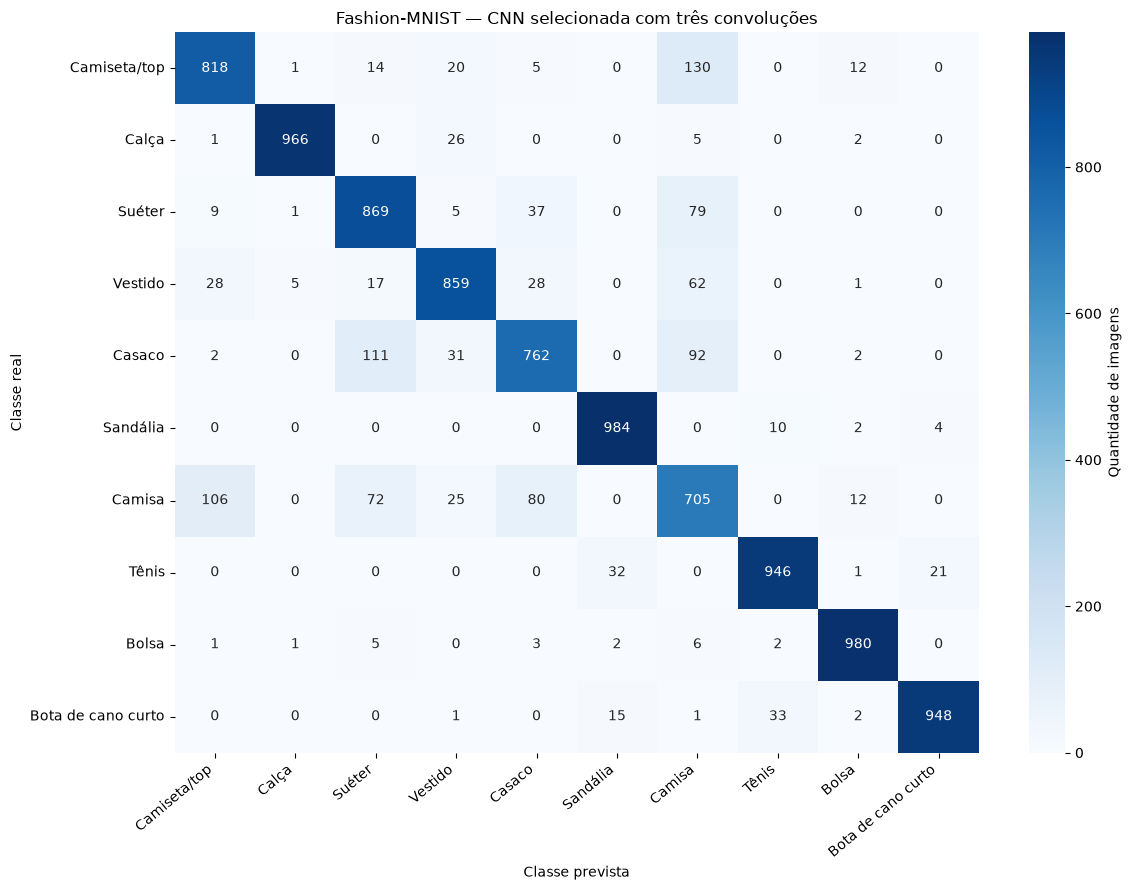

In [3]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Mesma sequência predict -> argmax -> confusion_matrix da Aula 23.
y_probs = modelo_final.predict(X_test, verbose=2)
y_pred = np.argmax(y_probs, axis=1)
cm = confusion_matrix(y_test, y_pred, labels=range(10))
assert cm.sum() == len(y_test)
assert np.isclose(np.trace(cm) / cm.sum(), test_acc)

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=NOMES_CLASSES, yticklabels=NOMES_CLASSES,
            cbar_kws={'label': 'Quantidade de imagens'}, ax=ax)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.set_title('Fashion-MNIST — CNN selecionada com três convoluções')
plt.setp(ax.get_xticklabels(), rotation=40, ha='right')
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(RESULTADOS / 'matriz_confusao_teste.png', dpi=150, bbox_inches='tight')
plt.show()

pd.DataFrame(cm, index=NOMES_CLASSES, columns=NOMES_CLASSES).to_csv(
    RESULTADOS / 'matriz_confusao_teste.csv', index_label='classe_real',
)


### Generalização e análise dos erros

O modelo selecionado foi a CNN com três convoluções, filtros 8/32/32,
64 neurônios densos, Dropout 0,3 e taxa de aprendizagem 0,001,
com os pesos da época 20.

| Conjunto | Loss | Acurácia |
| --- | ---: | ---: |
| Validação | 0,3084 | 89,21% |
| Teste — 10.000 imagens | 0,3448 | 88,37% |

No teste, a rede acertou **8.837 imagens e errou 1.163**. A acurácia ficou
0,84 ponto percentual abaixo da validação, com aumento da perda. Consideramos
o resultado satisfatório: o desempenho próximo entre os conjuntos indica
generalização para imagens do Fashion-MNIST que não participaram do treino.
Isso não garante o mesmo resultado em fotografias reais de roupas.

As confusões mais frequentes foram:

| Classe real | Classe prevista | Imagens |
| --- | --- | ---: |
| Camiseta/top | Camisa | 130 |
| Casaco | Suéter | 111 |
| Camisa | Camiseta/top | 106 |
| Casaco | Camisa | 92 |
| Camisa | Casaco | 80 |

Essas peças possuem contornos semelhantes, que podem ser difíceis de distinguir
em imagens pequenas e em escala de cinza. Camisa teve o menor número de acertos,
com 705 em 1.000 imagens. Sandália teve 984 acertos, e Bolsa, 980. A matriz
mostra, assim, diferenças de dificuldade que a acurácia global não revela.

A primeira busca havia obtido 85,80% de acurácia no teste, com perda 0,4027.
A configuração selecionada após a comparação de profundidades chegou a 88,37%,
mas também recebeu mais épocas de treinamento. Não podemos atribuir essa
diferença apenas ao número de camadas. O teste já havia sido consultado na
primeira rodada; a seleção da nova rede usou exclusivamente a validação.

### Conclusões

A MLP aprendeu padrões úteis, mas apresentou sobreajuste após a época 6.
A CNN com aumento de dados teve menor perda e acurácia de validação um pouco
maior na última época. A busca inicial destacou a taxa de aprendizagem 0,001
no orçamento de cinco épocas. Ao comparar profundidades com 20 épocas,
a rede de três convoluções apresentou a maior acurácia de validação, enquanto
a quarta camada não trouxe ganho.

O melhor modelo da busca atingiu 88,37% no teste. A vantagem na validação sobre
a CNN inicial foi pequena, e as confusões entre peças semelhantes continuaram
como a principal dificuldade. As conclusões se limitam à divisão dos dados
e às execuções realizadas.

## 7. Referências e uso de IA

- Nathalia da Cruz Alves. Enunciado do Trabalho Prático 2, slides da disciplina
  Sistemas Inteligentes e aulas práticas: Aula 19 — Perceptron;
  Aula 21 — CNN; Aula 23 — Treinamento de modelos. As implementações dessas
  aulas serviram de base para a MLP, a CNN, o aumento de dados, a busca de
  hiperparâmetros e a avaliação.
- Han Xiao, Kashif Rasul e Roland Vollgraf (2017).
  [Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms](https://arxiv.org/abs/1708.07747).
- [Repositório oficial do Fashion-MNIST: dados, classes e checksums](https://github.com/zalandoresearch/fashion-mnist).
- **OpenAI Codex:** utilizado como apoio à pesquisa e ao desenvolvimento do trabalho, auxiliando na adaptação dos códigos das aulas ao Fashion-MNIST, na execução dos experimentos, na documentação e na interpretação dos resultados.